In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# --- Project root (robust to folder moves) ---
# Default to the known location; fall back to the current working directory
# if the project has been moved again (launch JupyterLab from the project folder).
PROJECT_ROOT = Path.home() / "Claude" / "Projects" / "Directed Study" / "Ransomware"
if not (PROJECT_ROOT / "features").exists():
    PROJECT_ROOT = Path.cwd()
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
import umap

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Paths
FEATURES_DIR = PROJECT_ROOT / "features"

# Class definitions
RANSOMWARE_CLASSES = ["WannaCry", "Ryuk", "REvil", "LockBit", "Darkside", "Conti"]
BENIGN_CLASSES     = ["AESCrypt", "Zip", "SDelete", "Firefox", "Office", "Idle"]
VARIANT_CLASSES    = [f"Conti_{i:02d}" for i in range(1, 8)]

# Colors and markers — same as notebook 02
CLASS_COLORS = {
    "WannaCry": "#e6194b", "Ryuk": "#f58231", "REvil": "#ffe119",
    "LockBit": "#bfef45",  "Darkside": "#3cb44b", "Conti": "#42d4f4",
    "AESCrypt": "#4363d8", "Zip": "#911eb4",    "SDelete": "#f032e6",
    "Firefox": "#a9a9a9",  "Office": "#9a6324",  "Idle": "#000075",
    "Conti_01": "#e6beff", "Conti_02": "#ffd8b1","Conti_03": "#fffac8",
    "Conti_04": "#aaffc3", "Conti_05": "#dcbeff","Conti_06": "#469990",
    "Conti_07": "#800000",
}
CLASS_MARKERS = {}
for c in RANSOMWARE_CLASSES: CLASS_MARKERS[c] = "o"
for c in BENIGN_CLASSES:     CLASS_MARKERS[c] = "s"
for c in VARIANT_CLASSES:    CLASS_MARKERS[c] = "*"

print("Imports loaded.")

/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu
Imports loaded.


In [2]:
meta_df = pd.read_csv(FEATURES_DIR / "metadata.csv")

# Load full (300, 23) sequences — NOT mean-aggregated
# This preserves temporal structure the autoencoder needs
sequences, labels, groups = [], [], []

for _, row in meta_df.iterrows():
    data = np.load(row["filepath"])   # shape (300, 23)
    sequences.append(data)
    labels.append(row["label"])
    groups.append(row["group"])

sequences = np.array(sequences, dtype=np.float32)  # (190, 300, 23)
labels    = np.array(labels)
groups    = np.array(groups)

print(f"Sequences shape: {sequences.shape}")
print(f"Labels: {np.unique(labels)}")

Sequences shape: (190, 300, 23)
Labels: ['AESCrypt' 'Conti' 'Conti_01' 'Conti_02' 'Conti_03' 'Conti_04' 'Conti_05'
 'Conti_06' 'Conti_07' 'Darkside' 'Firefox' 'Idle' 'LockBit' 'Office'
 'REvil' 'Ryuk' 'SDelete' 'WannaCry' 'Zip']


In [3]:
# Fit scaler on original training data only (exclude variants)
train_mask = groups == "original"

# Flatten to (N*300, 23) to fit scaler, then reshape back
N, T, F = sequences.shape   # (190, 300, 23)

seqs_flat = sequences.reshape(-1, F)             # (190*300, 23)
scaler    = StandardScaler()
scaler.fit(seqs_flat[np.repeat(train_mask, T)])  # fit on original only

seqs_scaled = scaler.transform(seqs_flat).reshape(N, T, F)

print(f"Scaled sequences shape: {seqs_scaled.shape}")
print(f"Training samples (original): {train_mask.sum()}")
print(f"Variant samples:             {(~train_mask).sum()}")

Scaled sequences shape: (190, 300, 23)
Training samples (original): 120
Variant samples:             70


In [4]:
class RanSMAPDataset(Dataset):
    def __init__(self, sequences, labels, mask=None):
        if mask is not None:
            sequences = sequences[mask]
            labels    = labels[mask]
        self.X = torch.tensor(sequences, dtype=torch.float32)
        self.y = labels

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Train dataset — original classes only
train_dataset = RanSMAPDataset(seqs_scaled, labels, mask=train_mask)
train_loader  = DataLoader(train_dataset, batch_size=16,
                           shuffle=True, drop_last=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Batch size: 16  —  Batches per epoch: {len(train_loader)}")

Training samples: 120
Batch size: 16  —  Batches per epoch: 8


In [5]:
class TimeSeriesAutoencoder(nn.Module):
    """
    Autoencoder for (T, F) time-series inputs.

    Encoder: flattens the (300, 23) sequence → projects to bottleneck
    Decoder: expands bottleneck back to (300, 23)

    Bottleneck dimension = 16
    This compressed representation is the embedding for visualization
    and zero-day detection via reconstruction error.
    """
    def __init__(self, seq_len=300, n_features=23, bottleneck_dim=16):
        super().__init__()
        self.seq_len       = seq_len
        self.n_features    = n_features
        self.bottleneck_dim = bottleneck_dim
        input_dim = seq_len * n_features   # 6900

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, bottleneck_dim),
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, input_dim),
        )

    def forward(self, x):
        # x: (batch, 300, 23)
        batch = x.shape[0]
        flat  = x.view(batch, -1)           # (batch, 6900)
        z     = self.encoder(flat)          # (batch, 16)
        recon = self.decoder(z)             # (batch, 6900)
        recon = recon.view(batch, self.seq_len, self.n_features)
        return recon, z

    def encode(self, x):
        batch = x.shape[0]
        flat  = x.view(batch, -1)
        return self.encoder(flat)

# Instantiate and move to GPU
model = TimeSeriesAutoencoder(seq_len=300, n_features=23, bottleneck_dim=16)
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {total_params:,}")
print(model)

Model parameters: 7,211,524
TimeSeriesAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=6900, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=16, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8

In [6]:
EPOCHS    = 100
LR        = 1e-3
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)

train_losses = []

print(f"Training for {EPOCHS} epochs on {device}...")
print(f"{'Epoch':>6}  {'Loss':>10}  {'LR':>10}")
print("-" * 32)

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0

    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)
        optimizer.zero_grad()
        recon, z = model(batch_x)
        loss = criterion(recon, batch_x)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    scheduler.step()

    if epoch % 10 == 0 or epoch == 1:
        current_lr = scheduler.get_last_lr()[0]
        print(f"{epoch:>6}  {avg_loss:>10.6f}  {current_lr:>10.6f}")

print("\nTraining complete.")

Training for 100 epochs on cpu...
 Epoch        Loss          LR
--------------------------------
     1    0.617101    0.001000
    10    0.415821    0.001000
    20    0.382719    0.001000
    30    0.356240    0.000500
    40    0.327700    0.000500
    50    0.313173    0.000500
    60    0.291468    0.000250
    70    0.295194    0.000250
    80    0.285769    0.000250
    90    0.276229    0.000125
   100    0.269290    0.000125

Training complete.


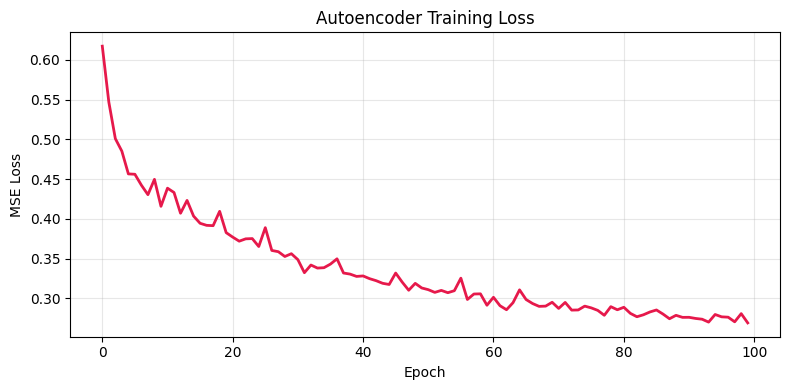

Final loss: 0.269290


In [7]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, color="#e6194b", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FEATURES_DIR / "autoencoder_loss.png", dpi=150)
plt.show()
print(f"Final loss: {train_losses[-1]:.6f}")

In [8]:
model.eval()

all_embeddings = []
all_recon_errors = []

full_dataset = RanSMAPDataset(seqs_scaled, labels)
full_loader  = DataLoader(full_dataset, batch_size=16, shuffle=False)

with torch.no_grad():
    for batch_x, _ in full_loader:
        batch_x = batch_x.to(device)
        recon, z = model(batch_x)

        # Embedding
        all_embeddings.append(z.cpu().numpy())

        # Reconstruction error per sample (mean squared error)
        recon_err = ((recon - batch_x) ** 2).mean(dim=(1, 2))
        all_recon_errors.append(recon_err.cpu().numpy())

embeddings   = np.concatenate(all_embeddings,   axis=0)  # (190, 16)
recon_errors = np.concatenate(all_recon_errors, axis=0)  # (190,)

print(f"Embeddings shape:    {embeddings.shape}")
print(f"Recon errors shape:  {recon_errors.shape}")
print(f"\nReconstruction error by group:")
print(f"  Original mean: {recon_errors[train_mask].mean():.4f}")
print(f"  Variant mean:  {recon_errors[~train_mask].mean():.4f}")

Embeddings shape:    (190, 16)
Recon errors shape:  (190,)

Reconstruction error by group:
  Original mean: 0.2106
  Variant mean:  0.8038


/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


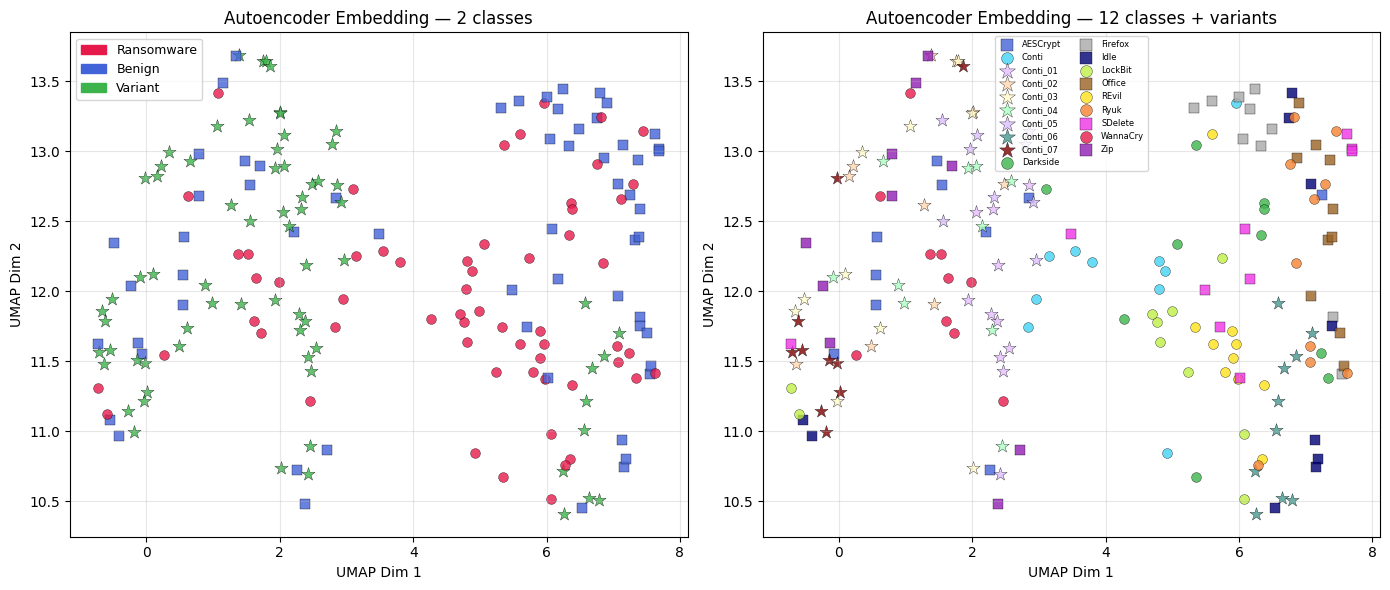

In [9]:
reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.1,
                    metric="euclidean", random_state=42)
emb_2d = reducer.fit_transform(embeddings)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, mode in zip(axes, ["2class", "12class"]):
    for label in np.unique(labels):
        mask   = labels == label
        color  = CLASS_COLORS.get(label, "#333333")
        marker = CLASS_MARKERS.get(label, "o")
        size   = 100 if marker == "*" else 50

        if mode == "2class":
            if label in RANSOMWARE_CLASSES:   c = "#e6194b"
            elif label in BENIGN_CLASSES:     c = "#4363d8"
            else:                             c = "#3cb44b"
        else:
            c = color

        ax.scatter(emb_2d[mask, 0], emb_2d[mask, 1],
                   c=c, marker=marker, s=size, alpha=0.8,
                   edgecolors="k", linewidths=0.3, label=label)

    if mode == "2class":
        ax.set_title("Autoencoder Embedding — 2 classes")
        patches = [
            mpatches.Patch(color="#e6194b", label="Ransomware"),
            mpatches.Patch(color="#4363d8", label="Benign"),
            mpatches.Patch(color="#3cb44b", label="Variant"),
        ]
        ax.legend(handles=patches, fontsize=9)
    else:
        ax.set_title("Autoencoder Embedding — 12 classes + variants")
        ax.legend(fontsize=6, ncol=2, markerscale=1.2)

    ax.set_xlabel("UMAP Dim 1")
    ax.set_ylabel("UMAP Dim 2")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FEATURES_DIR / "autoencoder_umap.png", dpi=150, bbox_inches="tight")
plt.show()

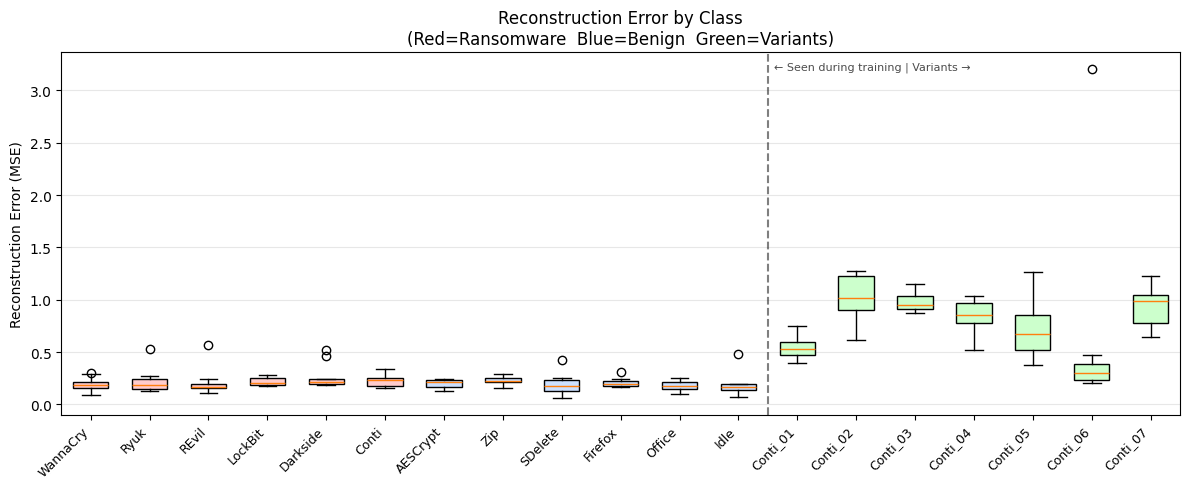

In [10]:
# This is the core zero-day detection mechanism
# High reconstruction error = sample looks unlike anything seen during training
# If variants have higher error than known classes → anomaly detection is viable

fig, ax = plt.subplots(figsize=(12, 5))

all_labels_sorted = RANSOMWARE_CLASSES + BENIGN_CLASSES + VARIANT_CLASSES
positions = []
errors_per_class = []
tick_labels = []

for i, label in enumerate(all_labels_sorted):
    mask = labels == label
    if mask.sum() == 0:
        continue
    errors_per_class.append(recon_errors[mask])
    tick_labels.append(label)
    positions.append(len(positions))

bp = ax.boxplot(errors_per_class, positions=positions,
                patch_artist=True, widths=0.6)

# Color boxes
for patch, label in zip(bp["boxes"], tick_labels):
    if label in RANSOMWARE_CLASSES:
        patch.set_facecolor("#ffcccc")
    elif label in BENIGN_CLASSES:
        patch.set_facecolor("#cce0ff")
    else:
        patch.set_facecolor("#ccffcc")

ax.set_xticks(positions)
ax.set_xticklabels(tick_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Reconstruction Error (MSE)")
ax.set_title("Reconstruction Error by Class\n(Red=Ransomware  Blue=Benign  Green=Variants)")
ax.grid(True, alpha=0.3, axis="y")

# Add vertical separator between original and variants
separator = len(RANSOMWARE_CLASSES) + len(BENIGN_CLASSES) - 0.5
ax.axvline(x=separator, color="black", linestyle="--", alpha=0.5, linewidth=1.5)
ax.text(separator + 0.1, ax.get_ylim()[1] * 0.95, "← Seen during training | Variants →",
        fontsize=8, alpha=0.7)

plt.tight_layout()
plt.savefig(FEATURES_DIR / "reconstruction_error.png", dpi=150, bbox_inches="tight")
plt.show()

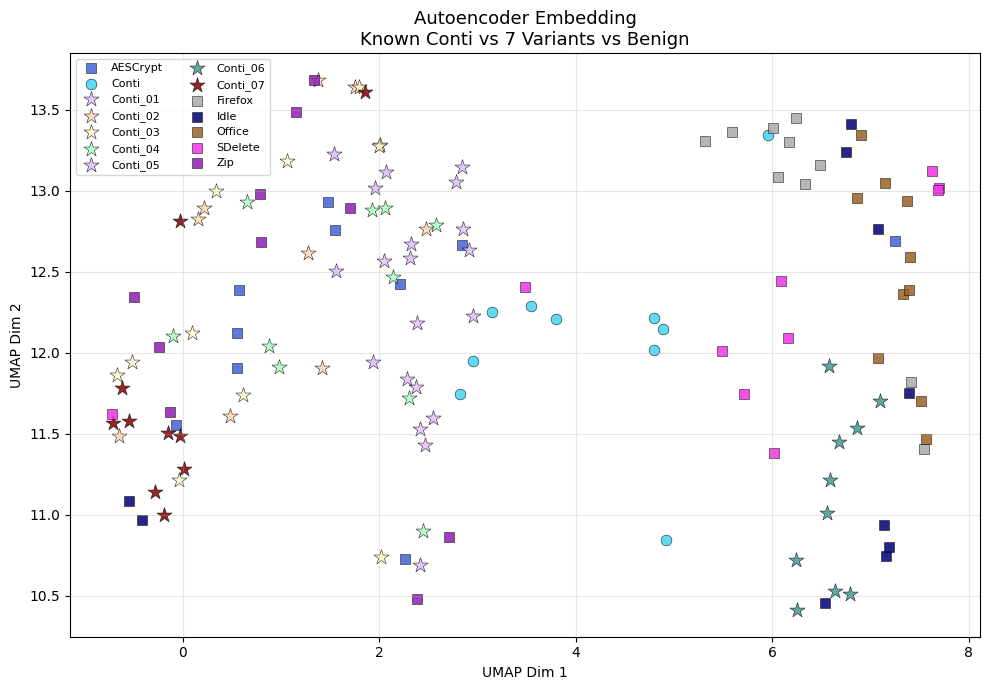

In [11]:
focus_labels = ["Conti"] + VARIANT_CLASSES + BENIGN_CLASSES
mask_focus   = np.isin(labels, focus_labels)

emb_focus    = emb_2d[mask_focus]
labels_focus = labels[mask_focus]

fig, ax = plt.subplots(figsize=(10, 7))

for label in np.unique(labels_focus):
    m      = labels_focus == label
    color  = CLASS_COLORS.get(label, "#333333")
    marker = CLASS_MARKERS.get(label, "o")
    size   = 130 if marker == "*" else 60

    ax.scatter(emb_focus[m, 0], emb_focus[m, 1],
               c=color, marker=marker, s=size,
               alpha=0.85, edgecolors="k", linewidths=0.4,
               label=label)

ax.set_title("Autoencoder Embedding\nKnown Conti vs 7 Variants vs Benign", fontsize=13)
ax.legend(fontsize=8, ncol=2)
ax.set_xlabel("UMAP Dim 1")
ax.set_ylabel("UMAP Dim 2")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FEATURES_DIR / "autoencoder_variants_focus.png", dpi=150, bbox_inches="tight")
plt.show()